In [ ]:
# Installing uv, a faster package manager
!pip install uv

# Ensuring colab does not restrict the versions of packages
import os
os.environ["UV_CONSTRAINT"] = ""
os.environ["UV_BUILD_CONSTRAINT"] = ""

# Installing the needed packages
!uv pip install --system numpy
!uv pip install --system --no-build-isolation "scikit-learn==1.9.0" "scipy==1.17.0" "iisignature==0.24" pandas matplotlib cvxpy

Using Python 3.13.16 environment at: /usr
Checked 1 package in 412ms
Using Python 3.13.16 environment at: /usr
Checked 6 packages in 296ms


In [ ]:
!git clone https://github.com/raulpek/ddif2.git

fatal: destination path 'ddif2' already exists and is not an empty directory.


In [ ]:
from __future__ import annotations
import io
import re
from pathlib import Path
import dataframe_image as dfi

import importlib.metadata as importlib_metadata
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Iterable, Callable

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import iisignature as signa
from scipy.optimize import minimize
import cvxpy as cvx_opt
from sklearn.covariance import LedoitWolf
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

try:
    SKLEARN_VERSION = importlib_metadata.version("scikit-learn")
except importlib_metadata.PackageNotFoundError:
    SKLEARN_VERSION = "unknown"

try:
    SCIPY_VERSION = importlib_metadata.version("scipy")
except importlib_metadata.PackageNotFoundError:
    SCIPY_VERSION = "unknown"

DEVELOPMENT_START = "2006-01-01"
DEVELOPMENT_END = "2015-12-31"

VALIDATION_START = "2016-01-01"
VALIDATION_END = "2020-12-31"

EVALUATION_START = "2021-01-01"
EVALUATION_END = "2025-12-31"

SYMBOLS = ["SPY", "AGG", "GLD", "BIL"]
RISKY_SYMBOLS = ["SPY", "AGG", "GLD"]
CASH = "BIL"
COST_BPS = 5.0
RANDOM_STATE = 42
path = "ddif2"

CACHE_DIR = Path("DDIF_project")
CACHE_DIR.mkdir(exist_ok=True)
# define the files to load
parquet_file_names = [
    "closes.parquet",
    "volumes.parquet",
    "ext_features.parquet",
    "etf_features.parquet",
    "alpha_ridge_sbg.parquet",
    "alpha_simple_sbg.parquet"
]

print({
    "scikit-learn": SKLEARN_VERSION,
    "SciPy": SCIPY_VERSION,
})

{'scikit-learn': '1.9.0', 'SciPy': '1.17.0'}


# HELPER FUNCTIONS

In [ ]:
def make_vc_tgt_df(tl, rebal_m, sim_pos, vol_tgt, b, bench_vol11, assets=RISKY_SYMBOLS):
  """
  Precompute volatilty corrected target weights
  """
  targets_dict = {}
  for i, date in enumerate(tl):
    if rebal_m[i] or i == 0:
      v = bench_vol11[sim_pos[i]]
      if v >= 1e-6:
        w_v = b * np.clip(vol_tgt / v, 0.0, 1.0)
      else:
        w_v = np.zeros(len(b))
      targets_dict[date] = w_v
  return pd.DataFrame(targets_dict, index=assets).T

def simulate_strategy(
    n_sim: int,
    trading_days: pd.DatetimeIndex,
    rebal_dates: pd.DatetimeIndex,
    R : np.ndarray,
    ffr_v : np.ndarray,
    target_weights: pd.DataFrame,
    cost_bps: float = 5.0,
    assets: list = [RISKY_SYMBOLS]
) -> dict[str, Any]:
    """
    Close-to-close simulator according to Devanathan et al. -paper.

    Parameters:
    returns : pd.DataFrame
        Daily returns to all assets incl. the daily interest of cash.
    targets : pd.DataFrame
        Target weights during the rebalancing day. Weights of SPY, AGG & GLD.
    cost_bps : float
        Whole spread (s) as basis points. Half spread (s/2) is used in the trading..
    cash_col : str
        Name of the cash column in the df.
    """
    n_assets = len(RISKY_SYMBOLS)
    cash = 1.0
    tw = target_weights[assets].dropna()

    # In the paper the cost is s/2. If cost_bps = 5, half-spead s/2 = 2.5 bps = 0.00025
    half_spread = (float(cost_bps) / 10_000.0) / 2.0
    navs = np.zeros(n_sim)
    hold = np.zeros(n_assets)
    comp = np.zeros((n_sim, n_assets))
    turn = np.zeros(n_sim)
    paid = np.zeros(n_sim)

    first = True

    for date in range(n_sim):
        date_curr = trading_days[date]

        # Gross return of the day and drifts
        cash *= 1.0 + ffr_v[date]
        hold = hold * (1.0 + R[date])
        nav = cash + hold.sum()
        if nav <= 0:
          raise RuntimeError("Negative Portfolio NAV")
        navs[date] = nav
        w = hold / nav # drifted weights prior to trading
        # Rebalancing and transaction fees
        if first: is_rebal = True
        elif isinstance(
            rebal_dates, (pd.DatetimeIndex, pd.Index)) or (
                isinstance(rebal_dates,(list,tuple))) and (
                    len(rebal_dates) > 0 and  not (
                        isinstance(rebal_dates[0], (bool, np.bool_)))
                    ): is_rebal = date_curr in rebal_dates

        else: is_rebal = bool(rebal_dates[date])
        if is_rebal:
            if date_curr in tw.index:
              w_new = tw.loc[date_curr].values
            else:
              w_new = np.zeros(n_assets)
            # Considering the cash: Calculating the weight difference only for the risky assets (non-cash)
            non_cash_diff = np.abs(w_new - w).sum()

            # Turnover = 0.5 * sum(|w_hat - w_drifted|)
            turnover = 0.5 * float(non_cash_diff)
            # cost = (s/2) * sum(|w_hat - w_drifted|) = 2 * (s/2) * turnover
            cost_fraction = half_spread * non_cash_diff

            if cost_fraction >= 1.0:
                raise RuntimeError("Transaction fees ate the whole portfolio.")

            # Cost is paid out of cash
            cash = (1.0 - w_new.sum() - cost_fraction) * nav
            hold = w_new * nav
            turn[date] = turnover
            paid[date] = cost_fraction
            w = w_new
            first = False
        else:
            pass

        # Net return = (1 + gross_return) * (1 - cost_fraction) - 1
        comp[date] = w

    # Results
    return {
        "nav": pd.Series(navs, index=trading_days),
        "comp": pd.DataFrame(comp, columns=RISKY_SYMBOLS, index=trading_days),
        "turnover": pd.Series(turn, index=trading_days),
        "cost": pd.Series(paid, index=trading_days)
    }


# Benchmark helper functions

In [ ]:
def optimize_step(obj_fn, constraints,weights, fallback):
  """
  Solve the optimization problem for the benchmark
  """
  problem = cvx_opt.Problem(obj_fn, constraints)
  try:
    problem.solve()
    if problem.status in ["optimal", "optimal_inaccurate"]:
      return weights.value.flatten()
    else:
      return fallback
  except cvx_opt.error.SolverError as e:
    return fallback


def run_markowitz(dates, alpha_table,
                  closes_df, R, ffr_series, trade_days,
                  b, sigma_tgt, s_obj, scale):
  """
  alpha_table: index are rebalance dates
  and columns are assets
  scale: makes a 21-day expected return
  """
  n_assets = len(b)
  w_curr = np.zeros(n_assets)
  hist_weights = {}
  r_full = (closes_df / closes_df.shift(1) - 1).fillna(0.0).values
  cash_account = 1.0
  prev_pos = -1

  for date in dates:
    if date not in alpha_table.index:
      continue

    # scale alpha forecast
    alpha = alpha_table.loc[date].values * scale

    # covariance and cholesky
    i_full = closes_df.index.get_loc(date)
    p = trade_days.get_loc(date)

    # previous weights drift
    hold = w_curr *np.prod(1.0  + R[prev_pos + 1: p+1], axis=0)
    cash_account = cash_account * np.prod(1.0 + ffr_series[prev_pos + 1: p+1])
    w_prev = hold / (cash_account + hold.sum())
    cash_ret = np.expm1x(21 * np.log1p(ffr_v[p]))

    # 11d return rolling window
    ret_window = r_full[i_full - 10:i_full + 1]
    v = np.sqrt((ret_window ** 2).mean(axis=0))
    C = np.cov((ret_window / v).T)
    Sigma_11d = np.outer(v,v) * C + 1e-14 * np.eye(n_assets)
    L_chol = np.linalg.cholesky(Sigma_11d)

    # solve the optimization problem
    w = cvx_opt.Variable(n_assets)
    a_t = alpha @ w
    cash_term = cash_ret * (1.0 - cvx_opt.sum(w))
    w_prev = w_curr
    to_penalty = (s_obj / 2.0) * cvx_opt.norm(w - w_prev,1)
    objective = cvx_opt.Maximize(a_t + cash_term - to_penalty)
    constraints = [
        w >= 0.0,
        cvx_opt.sum(w) <= 1.0,
        cvx_opt.norm(w - cvx_opt.sum(w)*b,1) <= cvx_opt.sum(w),
        cvx_opt.norm(L_chol.T @ w, 2) <= sigma_tgt
    ]
    if w_curr is not None:
      fallback = w_curr
    else:
      fallback = b
    w_curr = optimize_step(
        objective,
        constraints,
        w,
        w_prev
    )
    cash_account = 1.0 - w_curr.sum() -0.5*s_obj *np.abs(w_curr - w_prev).sum()
    prev_pos = p
    hist_weights[date] = w_curr

    res_df = pd.DataFrame(hist_weights).T
    res_df.columns = RISKY_SYMBOLS
  return res_df


In [ ]:
def sigma_11d(i_full, daily_rets):
  """
  11-day covariance
  """
  Rw = daily_rets[i_full - 10:i_full+1]
  v = np.sqrt((Rw ** 2).mean(axis=0))
  C = np.cov((Rw / v).T)
  covariance = np.outer(v,v) * C + 1e-14 * np.eye(3)
  return covariance

_cholesky_cache = {}
def cholesky_at(i_full):
  if i_full not in _cholesky_cache:
    _cholesky_cache[i_full] = np.linalg.cholesky(sigma_11d(i_full, returns_full))
  return _cholesky_cache[i_full]

In [ ]:
def solve_bm_optimization(obj_fn, constraints, weights, fallback):
  """
  Solve the optimization problem for the benchmark
  """
  problem = cvx_opt.Problem(obj_fn, constraints)
  try:
    problem.solve()
    if problem.status in ["optimal", "optimal_inaccurate"]:
      return weights.value.flatten()
    else:
      return fallback
  except cvx_opt.error.SolverError as e:
    return fallback

def create_bm_portfolios(trade_d, daily_rets,rebal_dates_m, rebal_dates_y,
                         vol_tgt, pos, n_sim, bench_vol11, alphas, b, closes,
                         ffr_series):
  """
  Generate the bencmarks
  - 50/30/20 volatility corrected version
  - simple Markovitz
  - Ridge-based Markovitz
  """
  bm_portfolios = {}
  costs = (COST_BPS /10000)
  n_sim = len(trade_d)
  yr_idx = np.where(rebal_dates_y)[0]
  yearly_dates = trade_d[yr_idx]
  # run 50/30/20 and 50/30/20 VC
  stand_targets = pd.DataFrame([b] * len(yearly_dates), index=yearly_dates, columns=RISKY_SYMBOLS)
  vc_targets = make_vc_tgt_df(trade_d, rebal_dates_m, pos, vol_tgt, b, bench_vol11)
  bm_portfolios["50/30/20"] = simulate_strategy(n_sim, trade_d, rebal_dates_y, daily_rets, ffr_series,
                                              stand_targets, cost_bps=5.0, assets=RISKY_SYMBOLS)
  bm_portfolios["50/30/20 VC"] = simulate_strategy(n_sim, trade_d, rebal_dates_m, daily_rets, ffr_series,
                                                          vc_targets, cost_bps=5.0, assets=RISKY_SYMBOLS)
  # run markowitz portfolios
  a_simple = alphas[0][RISKY_SYMBOLS]
  a_ridge = alphas[1][RISKY_SYMBOLS]
  posi_sel = np.where(rebal_dates_m | (np.arange(n_sim) == 0))[0]
  sel_dates = trade_d[posi_sel]
  simp_mark = run_markowitz(dates=sel_dates, alpha_table=a_simple.loc[sel_dates],
                            closes_df=closes, R=daily_rets, ffr_series=ffr_series,
                            trade_days=trade_d, b=b, sigma_tgt=vol_tgt, s_obj=costs,
                            scale=21.0)
  ridg_mark = run_markowitz(dates=sel_dates, alpha_table=a_ridge.loc[sel_dates],
                            closes_df=closes, R=daily_rets, ffr_series=ffr_series,
                            trade_days=trade_d,
                            b=b, sigma_tgt=vol_tgt, s_obj=costs, scale=21.0 /252.0)

  simp_mark.columns = RISKY_SYMBOLS
  ridg_mark.columns = RISKY_SYMBOLS
  bm_portfolios["Simple Markowitz"] = simulate_strategy(n_sim, trade_d, rebal_dates_m,
                                                        daily_rets, ffr_series,
                                                        simp_mark,cost_bps=5.0,
                                                        assets=RISKY_SYMBOLS)
  bm_portfolios["Ridge Markowitz"] = simulate_strategy(n_sim, trade_d, rebal_dates_m,
                                                        daily_rets, ffr_series,
                                                        ridg_mark,cost_bps=5.0,
                                                        assets=RISKY_SYMBOLS)
  return bm_portfolios

# 1. Data treatment

In [ ]:
# Load the data
closes  = pd.read_parquet(f"{path}/closes.parquet")[RISKY_SYMBOLS]
volumes = pd.read_parquet(f"{path}/volumes.parquet")[RISKY_SYMBOLS]
ffr_all = pd.read_parquet(f"{path}/ffr.parquet")["FFR"]
ext_features = pd.read_parquet(f"{path}/ext_features.parquet").reindex(closes.index)
etf_features = pd.read_parquet(f"{path}/etf_features.parquet").reindex(closes.index)
alpha_ridge_src = pd.read_parquet(f"{path}/alpha_ridge_sbg.parquet").reindex(closes.index)[RISKY_SYMBOLS]
alpha_simple_src = pd.read_parquet(f"{path}/alpha_simple_sbg.parquet").reindex(closes.index)[RISKY_SYMBOLS]
closes_eval = pd.read_parquet(f"{path}/closes_eval.parquet")[RISKY_SYMBOLS]

1.1 Define trading dates, rebalance dates and compute returns

In [ ]:
trading_days = closes.loc[DEVELOPMENT_START:EVALUATION_END].index
sim_pos = closes.index.get_indexer(trading_days)
n_sim = len(trading_days)

# All of the 3 risky asset's assets daily gross returns
c_f = closes.loc[trading_days].ffill().bfill()
returns_full_period = c_f.pct_change().fillna(0.0).values
ffr_v = ffr_all.reindex(trading_days).values.astype(float).copy()
ffr_v[0] = 0.0
ffrs_v = pd.Series(ffr_v, index=trading_days)

per_month = pd.Series(trading_days).dt.to_period("M")
rebal_m = (~per_month.duplicated(keep="last")).values
per_year = pd.Series(trading_days).dt.to_period("Y")
rebal_y = (~per_year.duplicated(keep="last")).values
rebal_dates = trading_days[rebal_m]
print("simulation days:", n_sim, "| monthly rebalances:", rebal_m.sum(), "| first/last:", rebal_dates[0].date(), rebal_dates[-1].date())

# full history simple daily returns
returns_full = closes / closes.shift(1) -1

simulation days: 5031 | monthly rebalances: 240 | first/last: 2006-01-31 2025-12-31


# 2. Create the benchmark portfolios

### 50/30/20, 50/30/20 VC, Simple Markowitz, Rigde-based Markowitz

In [ ]:
# 50/30/20 fixed weight
B = np.array([0.5, 0.3, 0.2])
bm_returns_full = (returns_full * B).sum(axis=1)
bm_vola11d = bm_returns_full.rolling(11).std().values
# past 21d avg dollar volume
avd_usd = (volumes * closes).rolling(21).mean().shift(1)
vola_21d = returns_full.rolling(21).std()

In [ ]:
# get the benchmarks
vola_target = 0.07 / np.sqrt(252) # ann 7% volatility target
alphas = [alpha_simple_src, alpha_ridge_src]
benchmarks = create_bm_portfolios(trading_days, returns_full_period,rebal_m,
                                  rebal_y,vola_target,
                                  sim_pos,n_sim, bm_vola11d, alphas, B,
                                  closes, ffr_v)

### Own Ridge

In [ ]:
class own_Ridge():
  def __init__(self, params, closes, rebal_dates):
    self.H = params[0]
    self.RIDGE = params[1]
    self.MIN_HIST = params[2]
    self.HALFLIFE = params[3]
    self.MIN_WINDOW = params[4]
    self.closes = closes
    self.rebal_d = rebal_dates
    self.W_full = 0.5 ** (np.arange(self.MIN_HIST - 1, -1, -1) / self.HALFLIFE)
  def make_targets(self, closes):
    tgt = self.closes.pct_change(self.H, fill_method=None).shift(-self.H) * 252.0 / self.H
    return tgt
  def run_length(self,valid):
    out = np.zeros(len(valid), dtype=int)
    for j in range(len(valid)):
        out[j] = (out[j - 1] + 1 if j > 0 else 1) if valid[j] else 0
    return out
  def fit(self, X, Y, rl, i):
    hi = i + 1 - self.H
    if i < self.MIN_WINDOW + self.H - 1 or hi <= 0:
        return None
    window = min(rl[hi - 1], self.MIN_HIST)
    if window < self.MIN_WINDOW:
        return None
    lo = hi - window
    Xw, Yw, x_now = X[lo:hi], Y[lo:hi], X[i]
    ft_mask = ~np.isnan(Xw).any(axis=0) & ~np.isnan(x_now)
    if not ft_mask.any():
        return None

    # floor on the scale
    feature_scale = np.maximum(np.std(Xw[:, ft_mask], axis=0), 1e-12)
    X_fit  = Xw[:, ft_mask] / feature_scale
    x_pred = x_now[ft_mask] / feature_scale
    row_w = self.W_full[-window:].copy()
    row_w /= row_w.sum()

    gram  = X_fit.T @ (row_w[:, None] * X_fit) # gram matrix
    cross = X_fit.T @ (row_w[:, None] * Yw)
    pen   = self.RIDGE * np.eye(X_fit.shape[1])
    try:
      beta = np.linalg.solve(gram + pen, cross)
    except np.linalg.LinAlgError:
      beta = np.linalg.lstsq(gram + pen, cross, rcond=None)[0]

    return ft_mask, feature_scale, beta

  def get_alpha(self, X, Y, pos):
    rl  = self.run_length(~np.isnan(Y).any(axis=1))
    out = np.zeros((len(pos), Y.shape[1]))
    for k, i in enumerate(pos):
        fit = self.fit(X, Y, rl, i)
        if fit is None:
            continue
        ft_mask, feature_scale, beta = fit
        out[k] = (X[i, ft_mask] / feature_scale) @ beta
    return out

  def build_alpha(self,
                  ext_features,
                  etf_features,
                  assets):
    for name, frame in (("ext_features", ext_features), ("etf_features", etf_features)):
        if not self.closes.index.equals(frame.index):
            raise ValueError(f"closes and {name} must share the same index.")
    etf_sel = etf_features[
        [c for c in etf_features.columns if any(f"_{a}" in c for a in assets)]
    ]
    X_df = pd.concat([ext_features, etf_sel], axis=1).replace(
        [np.inf, -np.inf], np.nan
    )
    Y = self.make_targets(self.closes[assets])
    X = X_df.to_numpy(dtype=np.float64)
    pos = self.closes.index.get_indexer(self.rebal_d)
    if (pos < 0).any():
        missing = rebal_dates[pos < 0]
        raise ValueError(f"Rebalance dates not in closes.index: {missing[:5]}")
    alpha_values = self.get_alpha(X, Y, pos)
    return pd.DataFrame(alpha_values, index=self.rebal_d, columns=assets)

In [ ]:
my_ridge = own_Ridge([100, 10.0, 512, 252, 100], closes, rebal_dates)
alpha_own = my_ridge.build_alpha(ext_features, etf_features, RISKY_SYMBOLS)

# 3. Signature methods

### 3.1 Creative design: signature representations

In [ ]:
from numpy.lib.stride_tricks import sliding_window_view
# realized variance clock
def variance_time(log_prices, N):
  """
  Log price path to uniform cumvar time
  """
  lp = np.asarray(log_prices, dtype=float)
  if lp.ndim == 1:
    lp = lp[:, None]
  returns = np.diff(lp, axis=0)
  step_var = np.sum(returns**2, axis=1)
  total = step_var.sum()
  if total <= 0:
    tau = np.linspace(0.0, 1.0, len(lp))
  else:
    tau = np.concatenate(([0.0],np.cumsum(step_var / total)))

  # define a grid
  grid = np.linspace(0.0, 1.0, N)
  out = np.empty((N, lp.shape[1]))
  for j in range(lp.shape[1]):
    out[:, j] = np.interp(grid, tau, lp[:, j]) # interpolate
  return out

  # lead-lag transform
def lead_lag_transf(path):
    """
    Basic lead-lag transformation
    """
    p = np.asarray(path, dtype=float)
    n = p.shape[0]
    d = p.shape[1]
    lead = np.empty((2*n - 1, d))
    lag = np.empty((2*n - 1, d))
    # leads from x0 to x_n-1
    lead[0::2] = p
    lead[1::2] = p[1:]
    # lags from x0 to x_n-1
    lag[0::2] = p
    lag[1::2] = p[:-1]
    # lead lag
    lead_lag = np.hstack([lead, lag])
    return lead_lag

### 3.2 Create the signature features

In [ ]:
def create_sig_feat(log_p, pos, win, N, depth, transform_fn="base"):
  n_time = log_p.shape[0]
  d = log_p.shape[1]
  # check which transform
  is_lag = (transform_fn == "ll")
  is_rvclock = (transform_fn == "rvclock")
  # expand dimension if lag
  if is_lag:
    stream_dim = 2*d
  else:
    stream_dim = d
  prepared = signa.prepare(stream_dim, depth)
  n_feat = signa.logsiglength(stream_dim, depth)

  window_a = sliding_window_view(log_p, window_shape=win, axis=0)
  windows_all = np.moveaxis(window_a, -1, 1)

  res = np.full((len(pos), n_feat),np.nan)

  for k,i in enumerate(pos):
    if i < win -1:
      continue
    w = windows_all[i - win + 1]
    w_rel = w - w[0]
    # apply custom transformation per family
    if is_rvclock:
      transformed = variance_time(w_rel, N)
    elif is_lag:
      transformed = lead_lag_transf(w_rel)
    else:
      transformed = w_rel

    phi_t = signa.logsig(transformed, prepared)
    res[k] = phi_t

  return res

In [ ]:
posi_sel  = np.where(rebal_m | (np.arange(n_sim) == 0))[0]
sel_dates = trading_days[posi_sel]
pos = closes.index.get_indexer(sel_dates)
L = 100 # window size of trading days
m = 2 # dimension
log_prix = np.log(closes[RISKY_SYMBOLS].astype(float)).to_numpy()
sig_arr = create_sig_feat(log_p=log_prix,pos=pos,win=L+1,
                          N=100, depth=2)

In [ ]:
# test as additional features
sig_df = pd.DataFrame(
    sig_arr, index=sel_dates,
    columns=[f"sig_{i}" for i in range(sig_arr.shape[1])]
)
ext_aug = pd.concat([ext_features, sig_df], axis=1)
alpha_aug = my_ridge.build_alpha(ext_aug, etf_features, RISKY_SYMBOLS)

### 3.3 Explicit non-signature controls

In [ ]:
# explicit non-signature controls
iu = np.triu_indices(len(RISKY_SYMBOLS))
def explicit_controls(win=None, blocks=("ret", "rcov"), names=False):
  """
  Non-signature controls on the log prices
  """
  labels = {}
  calc = {}

  # create labels
  ret_labels = [f"ret({a})" for a in RISKY_SYMBOLS]
  rcov_labels = [f"rcov({a},{b})" for i, a in enumerate(RISKY_SYMBOLS) for b in RISKY_SYMBOLS[i:]]
  lag_labels = [f"lag({a},{c})" for a in RISKY_SYMBOLS for c in RISKY_SYMBOLS]
  varw_labels = [f"varw({a})" for a in RISKY_SYMBOLS]
  calw_labels = [f"calw{a}" for a in RISKY_SYMBOLS]

  # add all together
  labels["ret"] = ret_labels
  labels["rcov"] = rcov_labels
  labels["lag"] = lag_labels
  labels["varw"] = varw_labels
  labels["calw"] = calw_labels
  if names:
    return [n for k in blocks for n in labels[k]]
  difference = np.diff(win, axis=0)
  q = (difference**2).sum(axis=1)

  # create calculations
  ret_cal =  difference[-1]
  rcov = (difference.T @ difference)[iu]
  lag1 = (difference[1:].T @ difference[:-1]).ravel()
  varw = difference.T @ q / max(q.sum(), 1e-16)
  calw = difference.T @ (np.arange(1, len(difference) + 1) / len(difference))

  # add all together
  calc["ret"] = ret_cal
  calc["rcov"] = rcov
  calc["lag"] = lag1
  calc["varw"] = varw
  calc["calw"] = calw

  # create an output
  parts = []
  for k in blocks:
    parts.append(calc[k])
  feat = np.concatenate(parts)
  return feat
#
def rolling_exp_controls(close_df, blocks, L=63):
  lp = np.log(close_df.values)
  names = explicit_controls(blocks=blocks, names=True)
  output = np.full((len(lp), len(names)), np.nan)
  for t in range(L, len(lp)):
    w = lp[t - L:t+1]
    if np.isnan(w).any():
      continue
    output[t] = explicit_controls(w - w[0], blocks=blocks, names=False)
  output_df = pd.DataFrame(output, index=close_df.index, columns=names)
  return output_df

# call to create the explicit controls
rolling_explicit = rolling_exp_controls(close_df=closes, blocks=("ret", "rcov", "lag"))

# to features to ridge
ext_control = pd.concat([ext_features, rolling_explicit], axis=1)
alpha_explicit = my_ridge.build_alpha(ext_control,etf_features=etf_features,
                                      assets=RISKY_SYMBOLS)

# 4. Experimental design

### 4.1 Group the models into a single dictionary

- orig = original Ridge
- orig+sig = + time-augment signature
- sig-only = time-augment signature-only
- orig+ll = + lead-lag log sig (creati.1)
- orig+RVexp = + expl.reali.cov (control1: removes cross-asset lead-lag timing and the area)
- orig+RVclk = + rv-lock log sig (creati.2)
- orig+Bexp = + explicit variance (control2: removes the shape dynamics of the risk clock)
- orig+endpoint (control3: removes path geometry)


In [ ]:
FAMILY = {}
FAMILY["endpoint"] = rolling_exp_controls(closes, blocks=["ret"],L=L)
FAMILY["rv_exp"] = rolling_exp_controls(closes, blocks=["ret", "rcov", "lag"],L=L)
FAMILY["clk_exp"] = rolling_exp_controls(closes,
                                         blocks=["ret", "rcov", "varw", "calw"],
                                         L=L)
lg_p_vals = np.log(closes.values)
pos_all = np.arange(len(closes))
res_time = create_sig_feat(lg_p_vals, pos_all, win=L+1,N=100,depth=2,
                           transform_fn="base")
FAMILY["sig_time"] = pd.DataFrame(res_time, index=closes.index)

# creative 1 lead-lag transformation
res_ll = create_sig_feat(lg_p_vals, pos_all, win=L+1, N=100,
                         depth=2, transform_fn="ll")
FAMILY["ll"] = pd.DataFrame(res_ll, index=closes.index)

# creative 2 realized-variance clock
res_rv = create_sig_feat(lg_p_vals, pos_all, win=L+1, N=100, depth=2,
                         transform_fn="rvclock")
FAMILY["rvclk"] = pd.DataFrame(res_rv, index=closes.index)

### 4.2 Portfolio simulations

In [ ]:
MODELS = {
    "orig": ([],True),
    "orig+sig": (["sig_time"],True),
    "sig_only": (["sig_time"],False),
    "orig+ll": (["ll"],True),
    "orig+RVexp": (["rv_exp"],True),
    "orig+RVclk": (["rvclk"],True),
    "orig+Bexp": (["clk_exp"],True),
    "orig+endpoint": (["endpoint"],True)
}

def base_features(ext_lag=0):
    etf_sel = etf_features[
    [c for c in etf_features.columns if any(f"_{a}" in c for a in RISKY_SYMBOLS)]
    ]
    X = pd.concat([ext_features, etf_features], axis=1)
    return X.replace([np.inf, -np.inf], np.nan)

def model_X(families, use_base=True):
  parts = ([base_features()] if use_base else []) + [FAMILY[f] for f in families]
  return pd.concat(parts, axis=1)


ALPHA ={}
for m, (fams, ub) in MODELS.items():
  if m == "orig":
    ALPHA[m] = alpha_own
  else:
    X_df = model_X(fams, use_base=ub)
    ALPHA[m] = my_ridge.build_alpha(X_df, etf_features, RISKY_SYMBOLS)

# portfolio simulations
RES = {}
for name, alpha_tbl in ALPHA.items():
  RES[name] = run_markowitz(
      dates=sel_dates,
      alpha_table=alpha_tbl.reindex(sel_dates).fillna(0.0),
      closes_df=closes,
      R=returns_full_period,
      ffr_series=ffr_v,
      trade_days=trading_days,
      b=B,
      sigma_tgt=vola_target,
      s_obj=(COST_BPS / 10000),
      scale=21.0/252.0
  )

# 5.0 Forecast diagnostics

In [ ]:
print("Forecast diagnostics:\n")
# Realized 100 day forward return for evaluation
y_true_df = closes[RISKY_SYMBOLS].pct_change(100).shift(-100) * (252.0 / 100.0)
y_true_sel = y_true_df.loc[sel_dates].dropna()

forecast_metrics = []

for m_name, alpha_df in ALPHA.items():
    # Aligning predictions and ground truth
    common_idx = alpha_df.index.intersection(y_true_sel.index)
    if len(common_idx) == 0:
        continue

    y_pred = alpha_df.loc[common_idx].values * (252.0 / 21.0) # Scaling to years
    y_true = y_true_sel.loc[common_idx].values

    mae = np.mean(np.abs(y_pred - y_true))
    rmse = np.sqrt(np.mean((y_pred - y_true)**2))
    sign_acc = np.mean(np.sign(y_pred) == np.sign(y_true))

    # Cosine Similarity
    dot_prod = np.sum(y_pred * y_true, axis=1)
    norm_pred = np.linalg.norm(y_pred, axis=1)
    norm_true = np.linalg.norm(y_true, axis=1)
    cos_sim = np.mean(dot_prod / (norm_pred * norm_true + 1e-12))

    forecast_metrics.append({
        "Model": m_name,
        "MAE": mae,
        "RMSE": rmse,
        "Sign Accuracy": sign_acc,
        "Cosine Similarity": cos_sim
    })

forecast_summary = pd.DataFrame(forecast_metrics).set_index("Model")
display(forecast_summary.style.format("{:.4f}"))

Forecast diagnostics:



,MAE,RMSE,Sign Accuracy,Cosine Similarity
Model,,,,
orig,1.3248,1.8391,0.6780,0.3480
orig+sig,1.3571,1.8951,0.6383,0.3157
sig_only,1.2621,1.6713,0.6340,0.2979
orig+ll,1.4166,2.0809,0.6099,0.2681
orig+RVexp,1.4109,2.2106,0.6496,0.3083
orig+RVclk,1.3574,1.8939,0.6397,0.3163
orig+Bexp,1.3933,2.0024,0.6340,0.2797
orig+endpoint,1.3521,1.8802,0.6596,0.3199


### 4.1 Forecast diagnostic per period

In [ ]:
SPLITS = {
    "Development (2006-2015)": (DEVELOPMENT_START, DEVELOPMENT_END),
    "Validation (2016-2020)":  (VALIDATION_START, VALIDATION_END),
    "Evaluation (2021-2025)":  (EVALUATION_START, EVALUATION_END)
}

print("Forecast diagnostics:\n")

# Realized 100 day forward return for evaluation
y_true_df = closes[RISKY_SYMBOLS].pct_change(100).shift(-100) * (252.0 / 100.0)
y_true_sel = y_true_df.loc[sel_dates].dropna()

# Going through all phases (Development, Validation, Evaluation)
for period_name, (start_date, end_date) in SPLITS.items():
  # Limiting to the days of the phase in question
  y_true_sub = y_true_df.loc[start_date:end_date].dropna()

  forecast_metrics = []

  for m_name, alpha_df in ALPHA.items():
      # Aligning predictions and ground truth
      common_idx = alpha_df.index.intersection(y_true_sub.index)
      if len(common_idx) == 0:
          continue

      y_pred = alpha_df.loc[common_idx].values * (252.0 / 21.0) # Scaling to years
      y_true = y_true_sel.loc[common_idx].values

      mae = np.mean(np.abs(y_pred - y_true))
      rmse = np.sqrt(np.mean((y_pred - y_true)**2))
      sign_acc = np.mean(np.sign(y_pred) == np.sign(y_true))

      # Cosine Similarity
      dot_prod = np.sum(y_pred * y_true, axis=1)
      norm_pred = np.linalg.norm(y_pred, axis=1)
      norm_true = np.linalg.norm(y_true, axis=1)
      cos_sim = np.mean(dot_prod / (norm_pred * norm_true + 1e-12))

      forecast_metrics.append({
          "Model": m_name,
          "MAE": mae,
          "RMSE": rmse,
          "Sign Accuracy": sign_acc,
          "Cosine Similarity": cos_sim
      })

  forecast_summary = pd.DataFrame(forecast_metrics).set_index("Model")
  print(f"\n* {period_name} ({start_date} – {end_date}) *")
  display(forecast_summary.style.format("{:.4f}"))

Forecast diagnostics:


* Development (2006-2015) (2006-01-01 – 2015-12-31) *


,MAE,RMSE,Sign Accuracy,Cosine Similarity
Model,,,,
orig,1.4279,2.0398,0.6917,0.3193
orig+sig,1.4494,2.0961,0.6750,0.2938
sig_only,1.4189,1.8639,0.6611,0.2665
orig+ll,1.5563,2.4112,0.6528,0.2824
orig+RVexp,1.6357,2.6866,0.6722,0.2727
orig+RVclk,1.4494,2.0934,0.6806,0.2956
orig+Bexp,1.5442,2.2914,0.6472,0.2628
orig+endpoint,1.4340,2.0615,0.6750,0.2851



* Validation (2016-2020) (2016-01-01 – 2020-12-31) *


,MAE,RMSE,Sign Accuracy,Cosine Similarity
Model,,,,
orig,0.9749,1.3265,0.7000,0.4069
orig+sig,1.0179,1.3879,0.6111,0.3705
sig_only,0.9068,1.1909,0.6167,0.3517
orig+ll,1.0850,1.4944,0.5556,0.2133
orig+RVexp,0.9358,1.2991,0.6611,0.3903
orig+RVclk,1.0187,1.3891,0.6056,0.3689
orig+Bexp,1.0198,1.4383,0.6389,0.3005
orig+endpoint,1.0182,1.3885,0.6833,0.4002



* Evaluation (2021-2025) (2021-01-01 – 2025-12-31) *


,MAE,RMSE,Sign Accuracy,Cosine Similarity
Model,,,,
orig,1.4814,1.8584,0.6242,0.3464
orig+sig,1.5257,1.9125,0.5879,0.3036
sig_only,1.3077,1.6754,0.5939,0.3076
orig+ll,1.4737,1.8388,0.5758,0.2968
orig+RVexp,1.4389,1.8138,0.5879,0.2965
orig+RVclk,1.5261,1.9130,0.5879,0.3039
orig+Bexp,1.4713,1.8494,0.6000,0.2942
orig+endpoint,1.5375,1.9308,0.6000,0.3082


# 6. Portfolio diagnostics

In [ ]:
print("Portfolio backtests (2006-2025)\n")

all_sim_results = {}
table_rows = []

# Running the simulations for all models
for m_name, w_df in RES.items():
    # Simulating the portfolio
    sim_res = simulate_strategy(
        n_sim=n_sim,
        trading_days=trading_days,
        rebal_dates=rebal_dates,
        R=returns_full_period,
        ffr_v=ffr_v,
        target_weights=w_df,
        cost_bps=5.0,
        assets=RISKY_SYMBOLS
    )
    all_sim_results[m_name] = sim_res

    # Financial metrics for the whole period (2006-2025)
    nav = sim_res["nav"]
    r = nav.pct_change().dropna()
    n_days = len(r)
    growth = nav.iloc[-1] / nav.iloc[0]
    cagr = growth ** (252.0 / n_days) - 1.0
    cash_growth = (1.0 + ffrs_v.loc[r.index]).prod()
    excess = (growth / cash_growth) ** (252.0 / n_days) - 1.0
    vol = r.std() * np.sqrt(252.0)
    sharpe = excess / vol
    max_dd = ((nav.cummax() - nav) / nav.cummax()).max()
    turnover = sim_res["turnover"].mean() * 252.0
    cost_bps_yr = sim_res["cost"].mean() * 252.0 * 10000.0
    avg_cash = (1.0 - sim_res["comp"].sum(axis=1)).mean()

    table_rows.append({
        "Model": m_name,
        "CAGR": cagr,
        "Ann. Vol": vol,
        "Sharpe": sharpe,
        "Max DD": max_dd,
        "Turnover": turnover,
        "Cost bps/yr": cost_bps_yr,
        "Avg Cash": avg_cash
    })

portfolio_summary = pd.DataFrame(table_rows).set_index("Model")
display(portfolio_summary.style.format("{:.4f}"))

Portfolio backtests (2006-2025)



,CAGR,Ann. Vol,Sharpe,Max DD,Turnover,Cost bps/yr,Avg Cash
Model,,,,,,,
orig,0.1142,0.0893,1.0688,0.1807,2.8459,14.2296,0.1538
orig+sig,0.1093,0.0883,1.0264,0.1822,2.6707,13.3534,0.1537
sig_only,0.0891,0.0889,0.7956,0.1822,2.4666,12.3330,0.1588
orig+ll,0.1019,0.0874,0.9537,0.1734,2.6541,13.2704,0.1730
orig+RVexp,0.1074,0.0887,1.0001,0.1823,2.7108,13.5540,0.1670
orig+RVclk,0.1093,0.0883,1.0254,0.1821,2.6698,13.3488,0.1540
orig+Bexp,0.1032,0.0883,0.9578,0.1818,2.7884,13.9420,0.1843
orig+endpoint,0.1067,0.0886,0.9933,0.1814,2.7585,13.7923,0.1626


In [ ]:
def bm_metrics(sim ,start,end):
    nav = sim["nav"]
    r = nav.pct_change().dropna()
    n_days = len(r)
    growth = nav.iloc[-1] / nav.iloc[0]
    cagr = growth ** (252.0 / n_days) - 1.0
    cash_growth = (1.0 + ffrs_v.loc[r.index]).prod()
    excess = (growth / cash_growth) ** (252.0 / n_days) - 1.0
    vol = r.std() * np.sqrt(252.0)
    sharpe = excess / vol
    max_dd = ((nav.cummax() - nav) / nav.cummax()).max()
    turnover = sim["turnover"].mean() * 252.0
    cost_bps_yr = sim["cost"].mean() * 252.0 * 10000.0
    avg_cash = (1.0 - sim["comp"].sum(axis=1)).mean()
    return [cagr, vol, sharpe, max_dd, turnover, cost_bps_yr, avg_cash]

add_bm = ["Simple Markowitz", "50/30/20", "50/30/20 VC"]
for bm in add_bm:
  res_bm = bm_metrics(benchmarks[bm], start=DEVELOPMENT_START,
                      end=EVALUATION_END)
  portfolio_summary.loc[bm, "CAGR"] = res_bm[0]
  portfolio_summary.loc[bm, "Ann. Vol"] = res_bm[1]
  portfolio_summary.loc[bm, "Sharpe"] = res_bm[2]
  portfolio_summary.loc[bm, "Max DD"] = res_bm[3]
  portfolio_summary.loc[bm, "Turnover"] = res_bm[4]
  portfolio_summary.loc[bm, "Cost bps/yr"] = res_bm[5]
  portfolio_summary.loc[bm, "Avg Cash"] = res_bm[6]
# show the updated list
display(portfolio_summary.style.format("{:.4f}"))

,CAGR,Ann. Vol,Sharpe,Max DD,Turnover,Cost bps/yr,Avg Cash
Model,,,,,,,
orig,0.1142,0.0893,1.0688,0.1807,2.8459,14.2296,0.1538
orig+sig,0.1093,0.0883,1.0264,0.1822,2.6707,13.3534,0.1537
sig_only,0.0891,0.0889,0.7956,0.1822,2.4666,12.3330,0.1588
orig+ll,0.1019,0.0874,0.9537,0.1734,2.6541,13.2704,0.1730
orig+RVexp,0.1074,0.0887,1.0001,0.1823,2.7108,13.5540,0.1670
orig+RVclk,0.1093,0.0883,1.0254,0.1821,2.6698,13.3488,0.1540
orig+Bexp,0.1032,0.0883,0.9578,0.1818,2.7884,13.9420,0.1843
orig+endpoint,0.1067,0.0886,0.9933,0.1814,2.7585,13.7923,0.1626
Simple Markowitz,0.1033,0.0931,0.9100,0.1585,2.8170,14.0849,0.1310


### 6.1 Portfolio evaluation on subperiods

In [ ]:
def evaluate_subperiods(all_sims, splits, ffr_series):
    subperiod_tables = {}

    for period_name, (start_p, end_p) in splits.items():
        rows = []
        for m_name, sim_res in all_sims.items():
            nav_sub = sim_res["nav"].loc[start_p:end_p]
            if len(nav_sub) == 0:
                continue

            r = nav_sub.pct_change().dropna()
            n_days = len(r)
            growth = nav_sub.iloc[-1] / nav_sub.iloc[0]
            cagr = growth ** (252.0 / n_days) - 1.0

            cash_growth = (1.0 + ffr_series.loc[r.index]).prod()
            excess = (growth / cash_growth) ** (252.0 / n_days) - 1.0
            vol = r.std() * np.sqrt(252.0)
            sharpe = excess / vol if vol > 0 else 0.0
            max_dd = ((nav_sub.cummax() - nav_sub) / nav_sub.cummax()).max()
            turnover = sim_res["turnover"].loc[start_p:end_p].mean() * 252.0

            rows.append({
                "Model": m_name,
                "CAGR": cagr,
                "Ann. Vol": vol,
                "Sharpe": sharpe,
                "Max DD": max_dd,
                "Turnover": turnover
            })

        df_sub = pd.DataFrame(rows).set_index("Model")
        subperiod_tables[period_name] = df_sub

    return subperiod_tables

# Calculating the subperiod results for the portfolios
sub_tables = evaluate_subperiods(all_sim_results, SPLITS, ffrs_v)

for period_name, df_sub in sub_tables.items():
    print(f"\n * {period_name.upper()} *")
    display(df_sub.style.format("{:.4f}"))


 * DEVELOPMENT (2006-2015) *


,CAGR,Ann. Vol,Sharpe,Max DD,Turnover
Model,,,,,
orig,0.1069,0.0874,1.0658,0.0933,2.7591
orig+sig,0.1072,0.0871,1.0729,0.0990,2.7273
sig_only,0.0897,0.0888,0.8569,0.1407,2.4835
orig+ll,0.0982,0.0873,0.9681,0.1148,2.7937
orig+RVexp,0.1051,0.0878,1.0411,0.1064,2.7979
orig+RVclk,0.1071,0.0871,1.0708,0.0985,2.7256
orig+Bexp,0.0956,0.0857,0.9562,0.1181,2.6961
orig+endpoint,0.0986,0.0863,0.9839,0.1023,2.8367



 * VALIDATION (2016-2020) *


,CAGR,Ann. Vol,Sharpe,Max DD,Turnover
Model,,,,,
orig,0.1257,0.0963,1.1722,0.1807,3.3218
orig+sig,0.1099,0.0936,1.0396,0.1822,2.8044
sig_only,0.1064,0.0958,0.9797,0.1822,2.5564
orig+ll,0.1014,0.0893,0.9955,0.1449,2.4628
orig+RVexp,0.1171,0.0943,1.1077,0.1823,2.7368
orig+RVclk,0.1099,0.0936,1.0396,0.1821,2.8032
orig+Bexp,0.1052,0.0961,0.9647,0.1818,3.2264
orig+endpoint,0.1137,0.0961,1.0520,0.1814,2.9541



 * EVALUATION (2021-2025) *


,CAGR,Ann. Vol,Sharpe,Max DD,Turnover
Model,,,,,
orig,0.1158,0.0857,0.9460,0.1274,2.5426
orig+sig,0.1100,0.0852,0.8859,0.1353,2.4229
sig_only,0.0692,0.0815,0.4413,0.1402,2.3427
orig+ll,0.1068,0.0856,0.8462,0.1512,2.5660
orig+RVexp,0.0991,0.0846,0.7674,0.1340,2.5101
orig+RVclk,0.1100,0.0852,0.8861,0.1352,2.4239
orig+Bexp,0.1134,0.0853,0.9237,0.1278,2.5343
orig+endpoint,0.1128,0.0852,0.9176,0.1278,2.4053


# 7.0 Plots

### 7.1 Cumulative net wealth

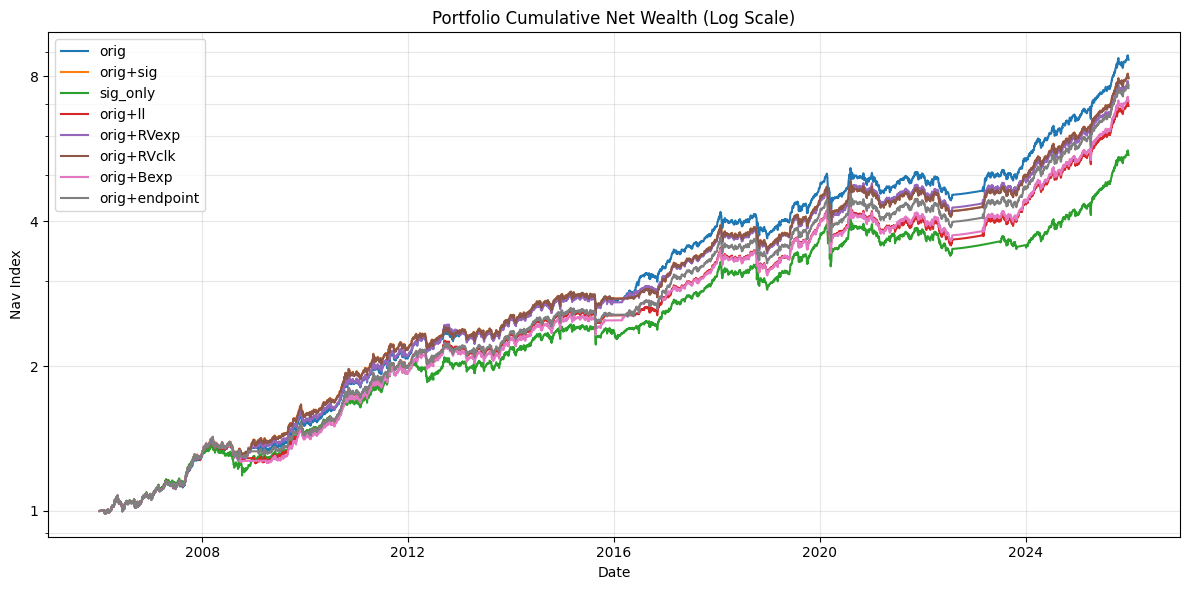

In [ ]:
plt.figure(figsize=(12, 6))
for m_name, sim_res in all_sim_results.items():
    plt.plot(sim_res["nav"].index, sim_res["nav"].values, label=m_name, lw=1.5)

plt.yscale("log")

plt.gca().yaxis.set_major_formatter(ticker.ScalarFormatter())
plt.gca().set_yticks([1, 2, 4, 8])

plt.title("Portfolio Cumulative Net Wealth (Log Scale)")
plt.xlabel("Date")
plt.ylabel("Nav Index")
plt.grid(True, which="both", alpha=0.3)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

### 7.1 Weights paths

### GROUP 1 #####



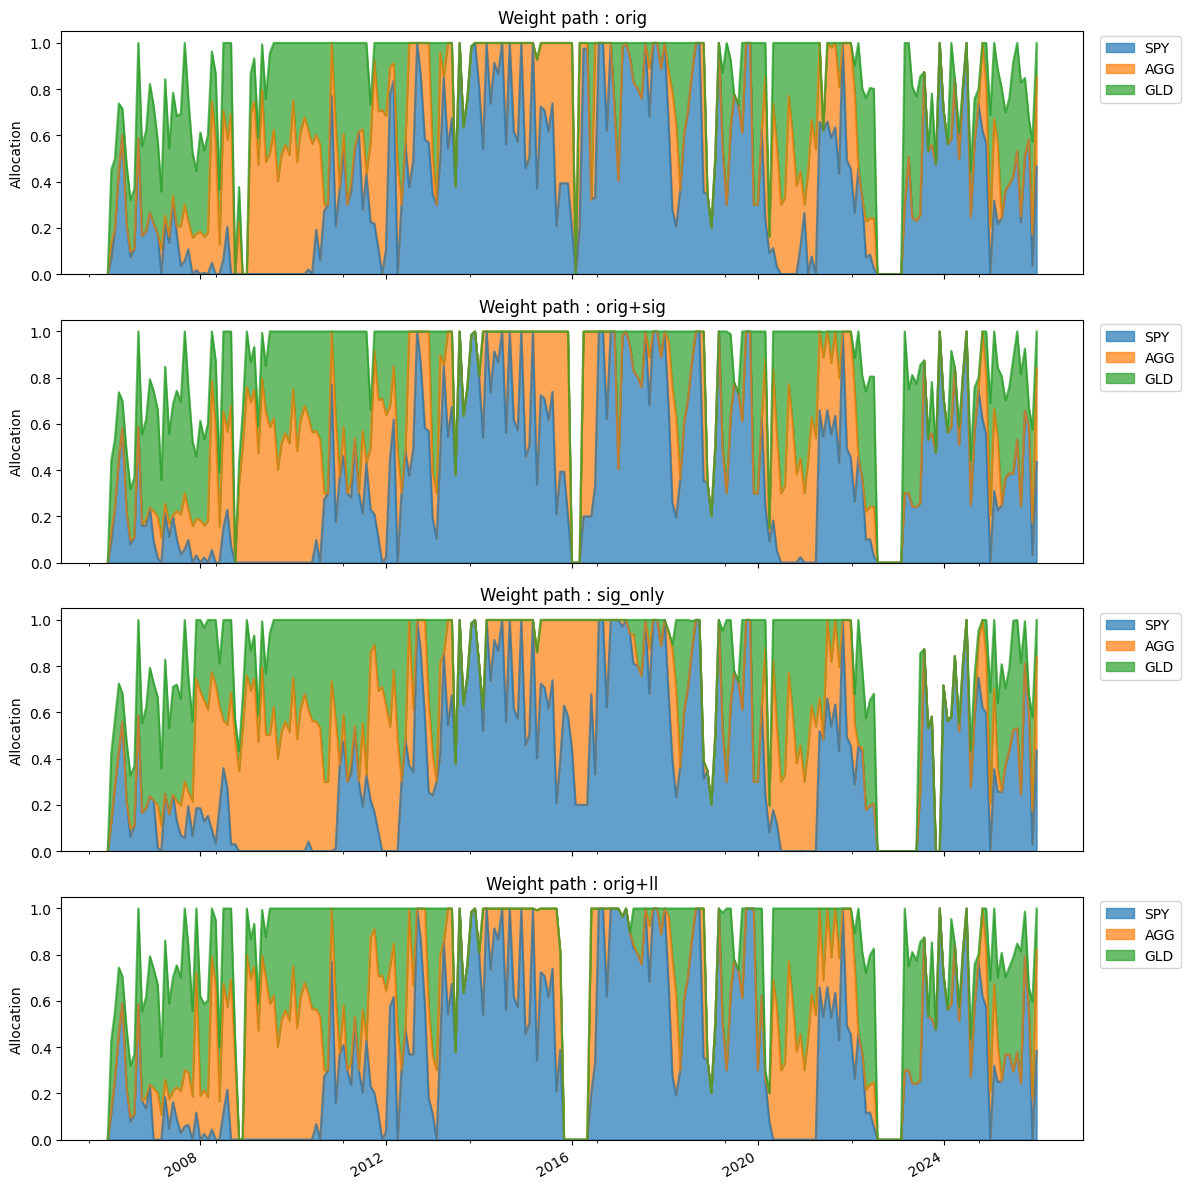

### GROUP 2 #####



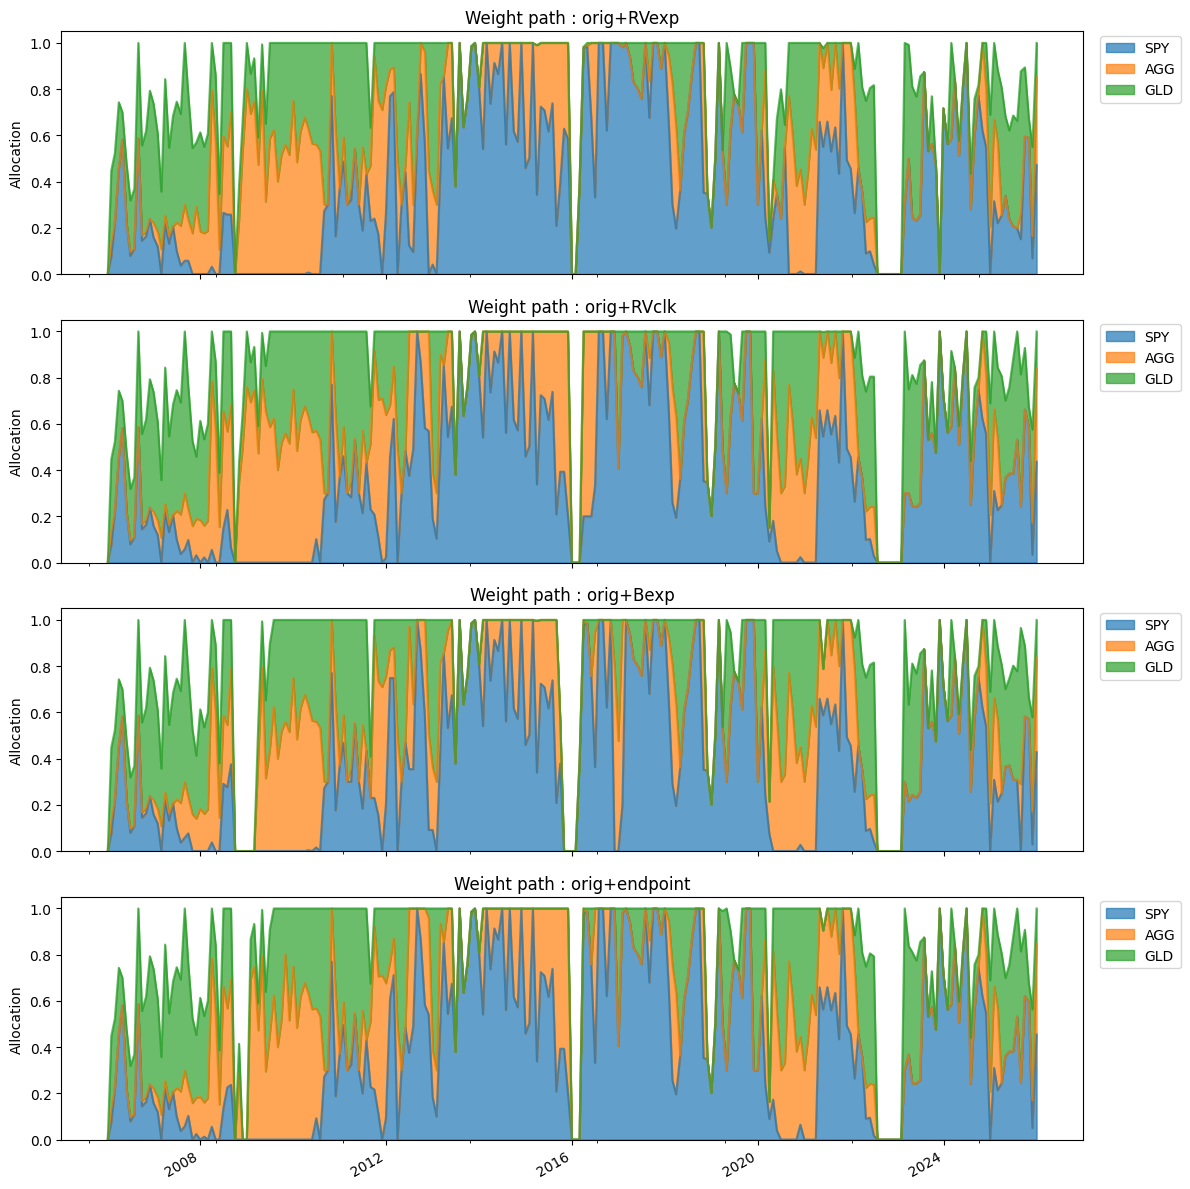

In [ ]:
model_names = list(RES.keys())
mid_point = len(model_names) // 2
group1 = model_names[:mid_point]
group2 = model_names[mid_point:]

print("### GROUP 1 #####\n")
# Figure 1: first group of model
fig1, axes1 = plt.subplots(nrows=len(group1), ncols=1,
                           figsize=(12, 3 * len(group1)), sharex=True)
for ax, name in zip(axes1, group1):
  w_df = RES[name]
  w_df.plot(kind="area", stacked=True, alpha=0.7, ax=ax)
  ax.set_ylabel("Allocation")
  ax.set_title(f"Weight path : {name}")
  ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.01))

plt.tight_layout()
plt.show()

print("### GROUP 2 #####\n")
# Figure 2: second group of model
fig2, axes2 = plt.subplots(nrows=len(group2), ncols=1,
                           figsize=(12, 3 * len(group2)), sharex=True)
for ax, name in zip(axes2, group2):
  w_df2 = RES[name]
  w_df2.plot(kind="area", stacked=True, alpha=0.7, ax=ax)
  ax.set_ylabel("Allocation")
  ax.set_title(f"Weight path : {name}")
  ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.01))

plt.tight_layout()
plt.show()

### 8. Performance relative to four transaction cost assumptions

In [ ]:
cost_scenarios = {
    "Zero Cost (0bps)": 0.0,
    "Low Cost (5bps)": 5.0,
    "Mid Cost (10bps)": 10.0,
    "High Cost (20bps)": 20.0
}

scenario_res = {}
for scenario_name, bps in cost_scenarios.items():
  s_obj_value = bps / 10000.0
  temp_sims = {}

  for model_name, alpha_table in ALPHA.items():
    w_df = run_markowitz(
        dates=sel_dates,
        alpha_table=alpha_table.reindex(sel_dates).fillna(0.0),
        closes_df=closes,
        R=returns_full_period,
        ffr_series=ffr_v,
        trade_days=trading_days,
        b=B,
        sigma_tgt=vola_target,
        s_obj=s_obj_value,
        scale=21.0/252.0
    )
    # simulate
    sim_res = simulate_strategy(
        n_sim=n_sim,
        trading_days=trading_days,
        rebal_dates=rebal_dates,
        R=returns_full_period,
        ffr_v=ffr_v,
        target_weights=w_df,
        cost_bps=bps,
        assets=RISKY_SYMBOLS
    )
    temp_sims[model_name] = sim_res

  # performance under cost scenario
  scenario_res[scenario_name] = evaluate_subperiods(temp_sims, SPLITS, ffrs_v)


def sensitivity_table(scenario_res, metric):
  target_period = "Evaluation (2021-2025)"
  comp_data = {}
  for scenario_name, subperiod_dict in scenario_res.items():
    if target_period not in subperiod_dict:
      continue
    else:
      df_sub = subperiod_dict[target_period][metric]
      comp_data[scenario_name] = df_sub
  cost_sensitivity_table = pd.DataFrame(comp_data).T
  return cost_sensitivity_table

# first with sharpe
print("* Sharpe comparison table *")
sharpe_sensi_table = sensitivity_table(scenario_res, "Sharpe")
display(sharpe_sensi_table.style.format("{:.4f}"))

# second with cagr
print("\n* CAGR comparison table *")
cagr_sensi_table = sensitivity_table(scenario_res, "CAGR")
display(cagr_sensi_table.style.format("{:.4f}"))

* Sharpe comparison table *


Model,orig,orig+sig,sig_only,orig+ll,orig+RVexp,orig+RVclk,orig+Bexp,orig+endpoint
Zero Cost (0bps),0.9549,0.9031,0.4423,0.7586,0.6710,0.9043,0.9335,0.9172
Low Cost (5bps),0.9460,0.8859,0.4413,0.8462,0.7674,0.8861,0.9237,0.9176
Mid Cost (10bps),0.9218,0.8584,0.4321,0.7832,0.7548,0.8586,0.8622,0.8920
High Cost (20bps),0.8864,0.7924,0.3462,0.7549,0.6951,0.7927,0.7963,0.8121



* CAGR comparison table *


Model,orig,orig+sig,sig_only,orig+ll,orig+RVexp,orig+RVclk,orig+Bexp,orig+endpoint
Zero Cost (0bps),0.1166,0.1116,0.0693,0.0991,0.0906,0.1117,0.1142,0.1128
Low Cost (5bps),0.1158,0.1100,0.0692,0.1068,0.0991,0.1100,0.1134,0.1128
Mid Cost (10bps),0.1135,0.1074,0.0681,0.1005,0.0979,0.1074,0.1074,0.1105
High Cost (20bps),0.1104,0.1016,0.0609,0.0977,0.0922,0.1016,0.1015,0.1034


### 8.1 Performance relative 50/30/20 benchmarks and original simple markowitz


In [ ]:
chosen_cost = "Low Cost (5bps)"
target_period = "Evaluation (2021-2025)"
model_period_data = scenario_res[chosen_cost][target_period]
df_models = pd.DataFrame(model_period_data)
# benchmarks for the same period
benchmark_eval = evaluate_subperiods(benchmarks, SPLITS, ffrs_v)
df_benchmarks = pd.DataFrame(benchmark_eval[target_period])

# add together, something was off with the titles
df_models.index = df_models.index.str.strip().str.title()
df_benchmarks.index = df_benchmarks.index.str.strip().str.title()
# final table
total_table = pd.concat([df_models, df_benchmarks], axis=0)
display(total_table.style.format("{:.4f}"))

,CAGR,Ann. Vol,Sharpe,Max DD,Turnover
Model,,,,,
Orig,0.1158,0.0857,0.9460,0.1274,2.5426
Orig+Sig,0.1100,0.0852,0.8859,0.1353,2.4229
Sig_Only,0.0692,0.0815,0.4413,0.1402,2.3427
Orig+Ll,0.1068,0.0856,0.8462,0.1512,2.5660
Orig+Rvexp,0.0991,0.0846,0.7674,0.1340,2.5101
Orig+Rvclk,0.1100,0.0852,0.8861,0.1352,2.4239
Orig+Bexp,0.1134,0.0853,0.9237,0.1278,2.5343
Orig+Endpoint,0.1128,0.0852,0.9176,0.1278,2.4053
50/30/20,0.1110,0.1009,0.7575,0.1886,0.0489


### 8.3 Comparison on cost bps (5ps) and period = 2021-2025

In [ ]:
chosen_cost = "Low Cost (5bps)"
target_period = "Evaluation (2021-2025)"

# 1. Haetaan mallien tiedot
model_period_data = scenario_res[chosen_cost][target_period]
df_models = pd.DataFrame(model_period_data)

# 2. Haetaan benchmark-tiedot ja luodaan niistä DataFrame
benchmark_eval = evaluate_subperiods(benchmarks, SPLITS, ffrs_v)
df_benchmarks = pd.DataFrame(benchmark_eval[target_period])

# Muotoillaan indeksit (mallien nimet) yhtenäisiksi
df_models.index = df_models.index.str.strip().str.title()
df_benchmarks.index = df_benchmarks.index.str.strip().str.title()

# 3. Korjataan Simple Markowitzin Turnover (lasketaan uudelleen simuloinnista)
if "Simple Markowitz" in benchmarks:
    sm_sim = benchmarks["Simple Markowitz"]

    # Tarkistetaan evaluation-periodin päivät
    eval_start, eval_end = SPLITS[target_period]

    # Lasketaan vuosittainen turnover painojen muutoksista evaluation-jaksolle
    if hasattr(sm_sim, 'comp') or isinstance(sm_sim, dict):
        w = sm_sim['comp'] if isinstance(sm_sim, dict) else sm_sim.weights
        w_eval = w.loc[eval_start:eval_end]

        # Vuotuinen turnover painojen itseisarvomuutosten summana
        calc_turnover = w_eval.diff().abs().sum(axis=1).mean() * 252 # tai rebalansointitiheyden mukaan

        # Päivitetään korjattu turnover-arvo taulukkoon (tai otetaan suoraan simulaatiosta jos kenttä löytyy)
        if 'Turnover' in df_benchmarks.columns and 'Simple Markowitz' in df_benchmarks.index:
            # Jos simulaatio-objektissa on jo oikea turnover-arvo:
            correct_to = sm_sim.get('Turnover', calc_turnover) if isinstance(sm_sim, dict) else getattr(sm_sim, 'turnover', calc_turnover)
            df_benchmarks.loc['Simple Markowitz', 'Turnover'] = correct_to

# 4. Yhdistetään taulukot
total_table = pd.concat([df_models, df_benchmarks], axis=0)

# 5. Remove Ridge markowitz because it is the same as "Orig"
total_table = total_table.drop(index=["Ridge Markowitz"], errors="ignore")

# Show the final table
display(total_table.style.format("{:.4f}"))

# Difference table
baseline = total_table.iloc[-3] # 50/30/20
baseline_values = {
    "CAGR": baseline["CAGR"],
    "Ann. Vol": baseline["Ann. Vol"],
    "Sharpe": baseline["Sharpe"],
    "Max DD": baseline["Max DD"],
    "Turnover": baseline["Turnover"]
}
diff_table = total_table.copy()
for col in diff_table.columns:
    diff_table[col] = diff_table[col] - baseline_values[col]
display(diff_table.style.format("{:.4f}"))

,CAGR,Ann. Vol,Sharpe,Max DD,Turnover
Model,,,,,
Orig,0.1158,0.0857,0.9460,0.1274,2.5426
Orig+Sig,0.1100,0.0852,0.8859,0.1353,2.4229
Sig_Only,0.0692,0.0815,0.4413,0.1402,2.3427
Orig+Ll,0.1068,0.0856,0.8462,0.1512,2.5660
Orig+Rvexp,0.0991,0.0846,0.7674,0.1340,2.5101
Orig+Rvclk,0.1100,0.0852,0.8861,0.1352,2.4239
Orig+Bexp,0.1134,0.0853,0.9237,0.1278,2.5343
Orig+Endpoint,0.1128,0.0852,0.9176,0.1278,2.4053
50/30/20,0.1110,0.1009,0.7575,0.1886,0.0489


,CAGR,Ann. Vol,Sharpe,Max DD,Turnover
Model,,,,,
Orig,0.0048,-0.0152,0.1885,-0.0612,2.4937
Orig+Sig,-0.0010,-0.0157,0.1284,-0.0533,2.3740
Sig_Only,-0.0418,-0.0194,-0.3162,-0.0484,2.2938
Orig+Ll,-0.0042,-0.0153,0.0887,-0.0374,2.5171
Orig+Rvexp,-0.0119,-0.0163,0.0099,-0.0546,2.4612
Orig+Rvclk,-0.0010,-0.0158,0.1286,-0.0534,2.3750
Orig+Bexp,0.0024,-0.0157,0.1662,-0.0608,2.4853
Orig+Endpoint,0.0018,-0.0157,0.1601,-0.0608,2.3564
50/30/20,0.0000,0.0000,0.0000,0.0000,0.0000
